In [96]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime

data_dir = Path("data")

if not data_dir.exists():
    data_dir = Path("../data")

files = sorted(
    data_dir.glob("uber-raw-data-???14.csv"),
    key = lambda file: datetime.strptime(
        file.stem.replace("uber-raw-data-",""),
        "%b%y"
    )
)

print("Total files:", len(files))

total_row = 0

for file in files:
    df = pd.read_csv(file)
    total_row += len(df)

    print("\nFile:", file.name)
    print("Columns:", df.columns.tolist())
    print(f"Row: {len(df):,}")

print(f"\ntotal_row: {total_row:,} row")

Total files: 6

File: uber-raw-data-apr14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 564,516

File: uber-raw-data-may14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 652,435

File: uber-raw-data-jun14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 663,844

File: uber-raw-data-jul14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 796,121

File: uber-raw-data-aug14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 829,275

File: uber-raw-data-sep14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 1,028,136

total_row: 4,534,327 row


In [97]:
# Data Quality Assessment (check missing value, duplicate ??)
missing_values_total = 0
duplicate_records_total = 0

for file in files:
    df = pd.read_csv(file)

    missing_values = df.isnull().sum()
    missing_values_count = df.isnull().sum().sum()
    duplicate = df.duplicated().sum()

    duplicate_rate = (duplicate/len(df) * 100)

    missing_values_total += missing_values_count
    duplicate_records_total += duplicate

    print(file.name, "\n")
    df.info()

    print(f"\nMissing Values:\n{missing_values}")
    print(f"\nDuplicate Records:\n{duplicate:,} ({duplicate_rate:.2f}%)\n")

print(f"Total Missing Values: {missing_values_total:,}")
print(f"Total Duplicate Records: {duplicate_records_total:,} ({(duplicate_records_total/len(df)) * 100:.2f}%)")

uber-raw-data-apr14.csv 

<class 'pandas.DataFrame'>
RangeIndex: 564516 entries, 0 to 564515
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Date/Time  564516 non-null  str    
 1   Lat        564516 non-null  float64
 2   Lon        564516 non-null  float64
 3   Base       564516 non-null  str    
dtypes: float64(2), str(2)
memory usage: 17.2 MB

Missing Values:
Date/Time    0
Lat          0
Lon          0
Base         0
dtype: int64

Duplicate Records:
7,749 (1.37%)

uber-raw-data-may14.csv 

<class 'pandas.DataFrame'>
RangeIndex: 652435 entries, 0 to 652434
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Date/Time  652435 non-null  str    
 1   Lat        652435 non-null  float64
 2   Lon        652435 non-null  float64
 3   Base       652435 non-null  str    
dtypes: float64(2), str(2)
memory usage: 19.9 MB

Missing Values:
Date/Time    0
Lat

In [114]:
# List check
quality_results = []

for file in files:
    df = pd.read_csv(file)

    missing_values = df.isnull().sum()
    missing_values_count = df.isnull().sum().sum()
    duplicate = df.duplicated().sum()

    quality_results.append({
        "Month": file.stem.split("-")[3],
        "Total Records": len(df),
        "Missing Values": missing_values_count,
        "Duplicate Records": duplicate
    })

quality_df = pd.DataFrame(quality_results)

quality_df["Duplicate Rate"] = (
    quality_df["Duplicate Records"]
    / quality_df["Total Records"] * 100
)

print(quality_df)

   Month  Total Records  Missing Values  Duplicate Records  Duplicate Rate
0  apr14         564516               0               7749        1.372680
1  may14         652435               0              10075        1.544215
2  jun14         663844               0              10686        1.609716
3  jul14         796121               0              14152        1.777619
4  aug14         829275               0              15882        1.915167
5  sep14        1028136               0              24037        2.337920


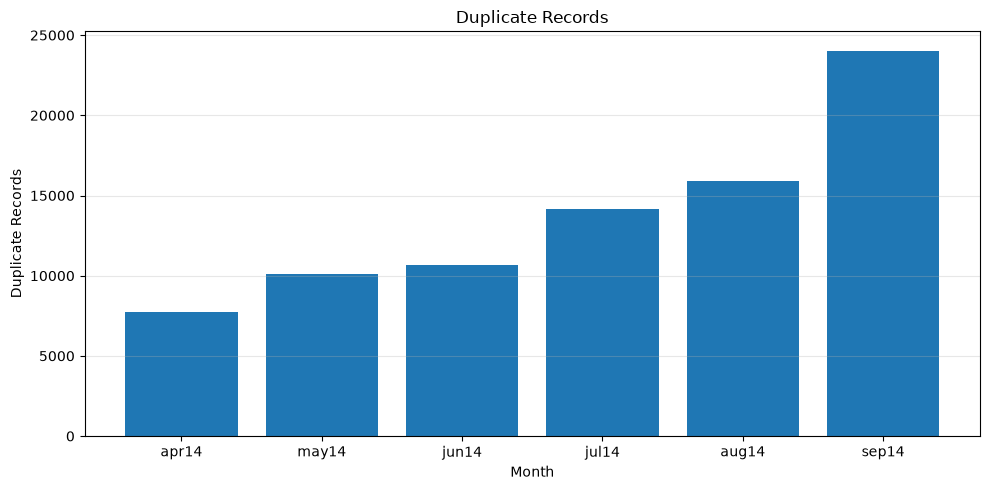

In [ ]:
#Uber Duplicate Records by Month with bar
plt.figure(figsize=(10, 5))

plt.bar(
    quality_df["Month"],
    quality_df["Duplicate Records"]
)

plt.title("Duplicate Records")
plt.xlabel("Month")
plt.ylabel("Duplicate Records")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

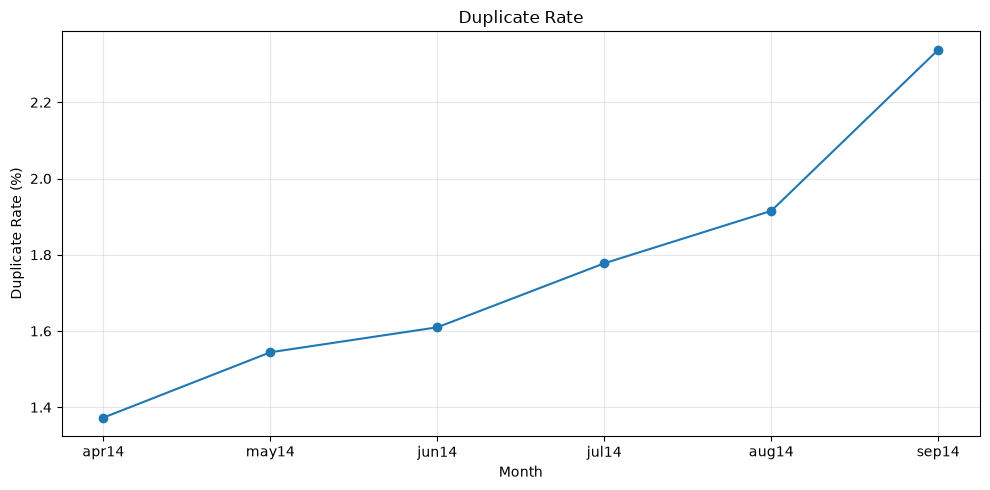

In [ ]:
#Uber Duplicate Rate by Month with plot
lt.figure(figsize=(10, 5))

plt.plot(
    quality_df["Month"],
    quality_df["Duplicate Rate"],
    marker="o"
)

plt.title("Duplicate Rate")
plt.xlabel("Month")
plt.ylabel("Duplicate Rate (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [138]:
# The Base codes are for the following Uber bases: New York City Taxi & Limousine Commission

# B02512 : Unter
# B02598 : Hinter
# B02617 : Weiter
# B02682 : Schmecken
# B02764 : Danach-NY
# B02765 : Grun
# B02835 : Dreist
# B02836 : Drinnen

bases = {"B02512", "B02598", "B02617", "B02682", "B02764", "B02765", "B02835", "B02836"}

invalid_total = {
    "Date/Time": 0,
    "Lat": 0,
    "Lon": 0,
    "Base": 0,
}

for file in files:
    df = pd.read_csv(file)

    dates = pd.to_datetime(
        df["Date/Time"],
        format="%m/%d/%Y %H:%M:%S",
        errors="coerce"
    )

    file_month = pd.to_datetime(
        file.stem[-5:],
        format="%b%y"
    ).to_period("M")

    invalid_date = (
        date.isna() |
        (dates.dt.to_period("M") != file_month)
    ).sum()

    invalid_lat = (~df["Lat"].between(-90, 90)).sum()
    invalid_lon = (~df["Lon"].between(-180, 180)).sum()
    invalid_base = (~df["Base"].isin(bases)).sum()

    invalid_total["Date/Time"] += invalid_date
    invalid_total["Lat"] += invalid_lat
    invalid_total["Lon"] += invalid_lon
    invalid_total["Base"] += invalid_base

    print(f"\nFile: {file.name}")
    print(f"Invalid Date/Time: {invalid_date:,}")
    print(f"Invalid Latitude: {invalid_lat:,}")
    print(f"Invalid Longitude: {invalid_lon:,}")
    print(f"Unexpected Base Codes: {invalid_base:,}")
    print("-" * 40)

print(f"\nTotal Validation Results: ")

for column, count in invalid_total.items():
    print(f"{column}: {count:,}")



File: uber-raw-data-apr14.csv
Invalid Date/Time: 0
Invalid Latitude: 0
Invalid Longitude: 0
Unexpected Base Codes: 0
----------------------------------------

File: uber-raw-data-may14.csv
Invalid Date/Time: 0
Invalid Latitude: 0
Invalid Longitude: 0
Unexpected Base Codes: 0
----------------------------------------

File: uber-raw-data-jun14.csv
Invalid Date/Time: 0
Invalid Latitude: 0
Invalid Longitude: 0
Unexpected Base Codes: 0
----------------------------------------

File: uber-raw-data-jul14.csv
Invalid Date/Time: 0
Invalid Latitude: 0
Invalid Longitude: 0
Unexpected Base Codes: 0
----------------------------------------

File: uber-raw-data-aug14.csv
Invalid Date/Time: 0
Invalid Latitude: 0
Invalid Longitude: 0
Unexpected Base Codes: 0
----------------------------------------

File: uber-raw-data-sep14.csv
Invalid Date/Time: 0
Invalid Latitude: 0
Invalid Longitude: 0
Unexpected Base Codes: 0
----------------------------------------

Total Validation Results: 
Date/Time: 0
Lat: 

In [139]:
for file in files:
    df = pd.read_csv(file)

    print(f"\nFile: {file.name}")
    print(f"Latitude: {df['Lat'].min()} to {df['Lat'].max()}")
    print(f"Longitude: {df['Lon'].min()} to {df['Lon'].max()}")
    print("-" * 40)


File: uber-raw-data-apr14.csv
Latitude: 40.0729 to 42.1166
Longitude: -74.7733 to -72.0666
----------------------------------------

File: uber-raw-data-may14.csv
Latitude: 40.1067 to 41.3225
Longitude: -74.929 to -72.1801
----------------------------------------

File: uber-raw-data-jun14.csv
Latitude: 39.9558 to 41.3199
Longitude: -74.8594 to -72.6966
----------------------------------------

File: uber-raw-data-jul14.csv
Latitude: 39.7214 to 41.3413
Longitude: -74.826 to -72.3097
----------------------------------------

File: uber-raw-data-aug14.csv
Latitude: 39.6569 to 41.3182
Longitude: -74.7737 to -72.3359
----------------------------------------

File: uber-raw-data-sep14.csv
Latitude: 39.9897 to 41.3476
Longitude: -74.7736 to -72.7163
----------------------------------------
